<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_project_feature.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

# 데이터 폴더 경로
data_path = '/content/drive/MyDrive/UDA-Project/UDA_final dataset'

# 최종 전처리 데이터 불러오기
csv_path = os.path.join(data_path, 'shorts_labeled_final.csv')

df = pd.read_csv(csv_path, dtype={'video_id': str})

# 데이터 크기 확인
print("데이터 크기:", df.shape)

# 컬럼 확인
print("\n컬럼 목록:")
print(df.columns.tolist())

데이터 크기: (1270, 28)

컬럼 목록:
['video_id', 'url', 'channel', 'channel_id', 'channel_url', 'title', 'description', 'tags', 'title_hashtags', 'desc_hashtags', 'drama_name', 'uploaded_at', 'days_since_upload', 'duration_sec', 'width', 'height', 'vcodec', 'video_file', 'source', 'view_count', 'like_count', 'comment_count', 'collected_at', 'channel_follower_count', 'group', 'log_views', 'z_in_group', 'pct_in_group']


In [4]:
import zipfile

video_dir = os.path.join(data_path, 'videos')

# 1. videos 폴더에 있는 MP4 확인
mp4_files = [
    f for f in os.listdir(video_dir)
    if f.lower().endswith('.mp4')
]

print("videos 폴더의 MP4 개수:", len(mp4_files))
print("MP4 파일 예시:", mp4_files[:5])

# 2. ZIP 파일 확인
zip_path = os.path.join(data_path, 'collected_videos.zip')

print("\nZIP 파일 존재 여부:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as z:
        zip_mp4 = [
            name for name in z.namelist()
            if name.lower().endswith('.mp4')
        ]

        print("ZIP 내부 MP4 개수:", len(zip_mp4))
        print("ZIP 내부 MP4 예시:", zip_mp4[:5])

videos 폴더의 MP4 개수: 5
MP4 파일 예시: ['-uefvTFvbcU.mp4', '0WQZGhkUT7Q.mp4', '-0wAxg8tynE.mp4', '28uYE6bjHKk.mp4', '--dCeRvCHTw.mp4']

ZIP 파일 존재 여부: True
ZIP 내부 MP4 개수: 1491
ZIP 내부 MP4 예시: ['videos/data-유희_--dCeRvCHTw.mp4', 'videos/data-유희_-36rUx30cyg.mp4', 'videos/data-유희_-D3_hyil_OY.mp4', 'videos/data-유희_-DQdT6DV92Y.mp4', 'videos/data-유희_-i2OI0zw73Y.mp4']


In [5]:
import re
import unicodedata

# 메타데이터의 영상 ID
video_ids = set(df['video_id'].dropna().astype(str))

# ZIP 안의 MP4 파일과 video_id 매칭
matched = {}
unmatched_files = []

with zipfile.ZipFile(zip_path, 'r') as z:
    zip_mp4 = [
        name for name in z.namelist()
        if name.lower().endswith('.mp4')
    ]

    for file_path in zip_mp4:
        filename = unicodedata.normalize(
            'NFC', os.path.basename(file_path)
        )

        # YouTube 영상 ID는 일반적으로 11자리
        # 파일명 끝의 11자리 ID 추출
        match = re.search(
            r'([A-Za-z0-9_-]{11})\.mp4$',
            filename
        )

        if match:
            video_id = match.group(1)

            if video_id in video_ids:
                matched.setdefault(video_id, []).append(file_path)
            else:
                unmatched_files.append(file_path)
        else:
            unmatched_files.append(file_path)

# 결과 출력
print("메타데이터 영상 수:", len(video_ids))
print("ZIP 내부 MP4 수:", len(zip_mp4))
print("매칭된 고유 영상 수:", len(matched))
print("매칭되지 않은 영상 ID 수:", len(video_ids - set(matched)))

# 중복 파일 확인
duplicates = {
    k: v for k, v in matched.items()
    if len(v) > 1
}

print("ZIP 내 중복 매칭 영상 수:", len(duplicates))

print("\n매칭 예시:")
for video_id in list(matched)[:5]:
    print(video_id, "→", matched[video_id][0])

print("\n매칭되지 않은 영상 ID 예시:")
print(list(video_ids - set(matched))[:10])

메타데이터 영상 수: 1270
ZIP 내부 MP4 수: 1491
매칭된 고유 영상 수: 1270
매칭되지 않은 영상 ID 수: 0
ZIP 내 중복 매칭 영상 수: 0

매칭 예시:
--dCeRvCHTw → videos/data-유희_--dCeRvCHTw.mp4
-36rUx30cyg → videos/data-유희_-36rUx30cyg.mp4
-D3_hyil_OY → videos/data-유희_-D3_hyil_OY.mp4
-DQdT6DV92Y → videos/data-유희_-DQdT6DV92Y.mp4
-i2OI0zw73Y → videos/data-유희_-i2OI0zw73Y.mp4

매칭되지 않은 영상 ID 예시:
[]


# 테스트 영상 1개

In [6]:
import cv2

# 테스트할 영상 ID
test_video_id = list(matched.keys())[0]

# ZIP 내부의 실제 파일 경로
test_zip_path = matched[test_video_id][0]

# 코랩 임시 폴더
test_dir = '/content/traditional_test'
os.makedirs(test_dir, exist_ok=True)

# ZIP에서 영상 1개만 꺼내기
test_video_path = os.path.join(
    test_dir,
    f'{test_video_id}.mp4'
)

with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(test_zip_path) as src:
        with open(test_video_path, 'wb') as dst:
            import shutil
            shutil.copyfileobj(src, dst)

print("테스트 영상 ID:", test_video_id)
print("영상 저장 경로:", test_video_path)
print("파일 크기(MB):",
      round(os.path.getsize(test_video_path) / 1024**2, 2))

# OpenCV로 영상 열기
cap = cv2.VideoCapture(test_video_path)

print("\n영상 열기 성공:", cap.isOpened())

if cap.isOpened():
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

    duration = frame_count / fps if fps > 0 else None

    print("FPS:", fps)
    print("전체 프레임 수:", frame_count)
    print("영상 길이(초):", duration)
    print("해상도:", int(width), "x", int(height))

cap.release()

테스트 영상 ID: --dCeRvCHTw
영상 저장 경로: /content/traditional_test/--dCeRvCHTw.mp4
파일 크기(MB): 2.17

영상 열기 성공: True
FPS: 29.97002997002997
전체 프레임 수: 1401.0
영상 길이(초): 46.746700000000004
해상도: 360 x 640


# 특징 추출 함수

In [7]:
def extract_basic_features(video_path, sample_interval=1.0):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        print("영상 열기 실패:", video_path)
        return None

    fps = cap.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        cap.release()
        return None

    brightness_values = []
    frame_diff_values = []

    previous_gray = None

    # 초 단위 간격으로 프레임 샘플링
    frame_step = max(1, round(fps * sample_interval))

    frame_idx = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame_idx % frame_step == 0:

            # 컬러 영상을 흑백으로 변환
            gray = cv2.cvtColor(
                frame, cv2.COLOR_BGR2GRAY
            )

            # 1. 평균 밝기
            brightness = gray.mean()
            brightness_values.append(brightness)

            # 2. 이전 샘플 프레임과의 차이
            if previous_gray is not None:
                diff = cv2.absdiff(gray, previous_gray)
                frame_diff_values.append(diff.mean())

            previous_gray = gray

        frame_idx += 1

    cap.release()

    if not brightness_values:
        return None

    return {
        'trad_brightness_mean': float(
            pd.Series(brightness_values).mean()
        ),
        'trad_brightness_std': float(
            pd.Series(brightness_values).std(ddof=0)
        ),
        'trad_frame_diff_mean': (
            float(pd.Series(frame_diff_values).mean())
            if frame_diff_values else 0.0
        )
    }

## 테스트 영상에 적용

In [8]:
basic_features = extract_basic_features(test_video_path)

print("영상 ID:", test_video_id)
print("\nTraditional 기본 특징:")
print(basic_features)

영상 ID: --dCeRvCHTw

Traditional 기본 특징:
{'trad_brightness_mean': 54.18861286569148, 'trad_brightness_std': 11.92812416270511, 'trad_frame_diff_mean': 27.976830370621986}


> OpenCV에서 일반적인 8비트 흑백 이미지는 각 픽셀의 밝기를 0~255 사이의 숫자로 표현

- 평균 밝기: 0에 가까우면 어둡고, 255에 가까우면 밝음
- 밝기 표준편차: 시간에 따라 평균 밝기가 얼마나 변하는지 나타내. 값이 클수록 밝기 변화가 큰 편
- 프레임 차이 평균: 1초 간격으로 추출한 프레임의 변화량
  - 값이 클수록 화면 변화가 크다는 뜻이지만, 인물 움직임과 컷 전환은 구분 불가

# 컷 빈도 추출 함수

- 연속된 두 프레임의 생상 히스토그램 차이로 컷 전환 탐지

In [9]:
def extract_cut_features(video_path, sample_fps=5, threshold=0.5):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return None

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)

    if fps <= 0 or total_frames <= 0:
        cap.release()
        return None

    duration = total_frames / fps
    frame_step = max(1, round(fps / sample_fps))

    previous_hist = None
    cut_count = 0
    cut_times = []
    frame_idx = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame_idx % frame_step == 0:

            # 영상 크기 축소
            frame = cv2.resize(frame, (160, 90))

            # HSV 색상 공간 변환
            hsv = cv2.cvtColor(
                frame, cv2.COLOR_BGR2HSV
            )

            # H, S 채널 히스토그램 계산
            hist = cv2.calcHist(
                [hsv], [0, 1], None,
                [30, 32],
                [0, 180, 0, 256]
            )

            cv2.normalize(hist, hist)

            if previous_hist is not None:

                similarity = cv2.compareHist(
                    previous_hist,
                    hist,
                    cv2.HISTCMP_CORREL
                )

                # 유사도가 낮으면 컷 전환으로 판단
                if similarity < threshold:
                    cut_count += 1
                    cut_times.append(frame_idx / fps)

            previous_hist = hist

        frame_idx += 1

    cap.release()

    return {
        'trad_cut_count': cut_count,
        'trad_cut_frequency': cut_count / duration,
        'trad_cut_times': cut_times
    }

- threshold=0.5는 테스트를 위한 기준값으로 추후 조정
- sample_fps=5 : 초당 약 5개의 프레임 분석

## 테스트 영상에 적용

In [10]:
cut_features = extract_cut_features(test_video_path)

print("영상 ID:", test_video_id)
print("컷 후보 개수:", cut_features['trad_cut_count'])
print("초당 컷 빈도:", round(cut_features['trad_cut_frequency'], 4))
print("컷 후보 시간(초):", cut_features['trad_cut_times'])

영상 ID: --dCeRvCHTw
컷 후보 개수: 0
초당 컷 빈도: 0.0
컷 후보 시간(초): []


- 색상 히스토그램 유사도가 높아서 일단 프레임 간 유사도 분포 확인하고 threshold 다시 설정

## 프레임 간 유사도 분포 확인 후 다시 테스트

In [11]:
def check_hist_similarity(video_path, sample_fps=5):

    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_step = max(1, round(fps / sample_fps))

    previous_hist = None
    similarities = []
    times = []

    frame_idx = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame_idx % frame_step == 0:

            frame = cv2.resize(frame, (160, 90))
            hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

            hist = cv2.calcHist(
                [hsv], [0, 1], None,
                [30, 32],
                [0, 180, 0, 256]
            )

            cv2.normalize(hist, hist)

            if previous_hist is not None:
                similarity = cv2.compareHist(
                    previous_hist,
                    hist,
                    cv2.HISTCMP_CORREL
                )

                similarities.append(similarity)
                times.append(frame_idx / fps)

            previous_hist = hist

        frame_idx += 1

    cap.release()

    return pd.DataFrame({
        'time_sec': times,
        'similarity': similarities
    })

In [12]:
similarity_df = check_hist_similarity(test_video_path)

print("유사도 통계:")
display(similarity_df['similarity'].describe())

print("\n유사도가 가장 낮은 10개 시점:")
display(similarity_df.nsmallest(10, 'similarity'))

유사도 통계:


,similarity
count,233.000000
mean,0.991252
std,0.012938
min,0.924463
25%,0.991088
50%,0.996741
75%,0.998736
max,0.999842



유사도가 가장 낮은 10개 시점:


,time_sec,similarity
176,35.4354,0.924463
178,35.8358,0.928942
150,30.2302,0.942350
138,27.8278,0.943083
106,21.4214,0.943868
187,37.6376,0.946318
33,6.8068,0.954981
115,23.2232,0.957565
107,21.6216,0.958810
133,26.8268,0.959603


- 최솟값이 0.9245
- 유사도가 가장 낮은 시점에 실제로 장면이 전환되었는지 눈으로 확인

### 유사도가 가장 낮은 시점의 프레임 확인

In [13]:
import matplotlib.pyplot as plt

def show_cut_candidates(video_path, similarity_df, n=5):

    cap = cv2.VideoCapture(video_path)

    # 유사도가 가장 낮은 시점 선택
    candidates = similarity_df.nsmallest(
        n, 'similarity'
    )

    fig, axes = plt.subplots(n, 2, figsize=(10, n * 3))

    for i, (_, row) in enumerate(candidates.iterrows()):

        time_sec = row['time_sec']

        # 컷 후보 직전과 직후 프레임
        times = [max(0, time_sec - 0.2), time_sec]

        for j, t in enumerate(times):

            cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
            ret, frame = cap.read()

            if ret:
                frame = cv2.cvtColor(
                    frame, cv2.COLOR_BGR2RGB
                )

                axes[i, j].imshow(frame)

            axes[i, j].axis('off')
            axes[i, j].set_title(
                f'{t:.2f} sec'
            )

        axes[i, 0].set_ylabel(
            f'Similarity: {row["similarity"]:.3f}'
        )

    cap.release()

    plt.tight_layout()
    plt.show()

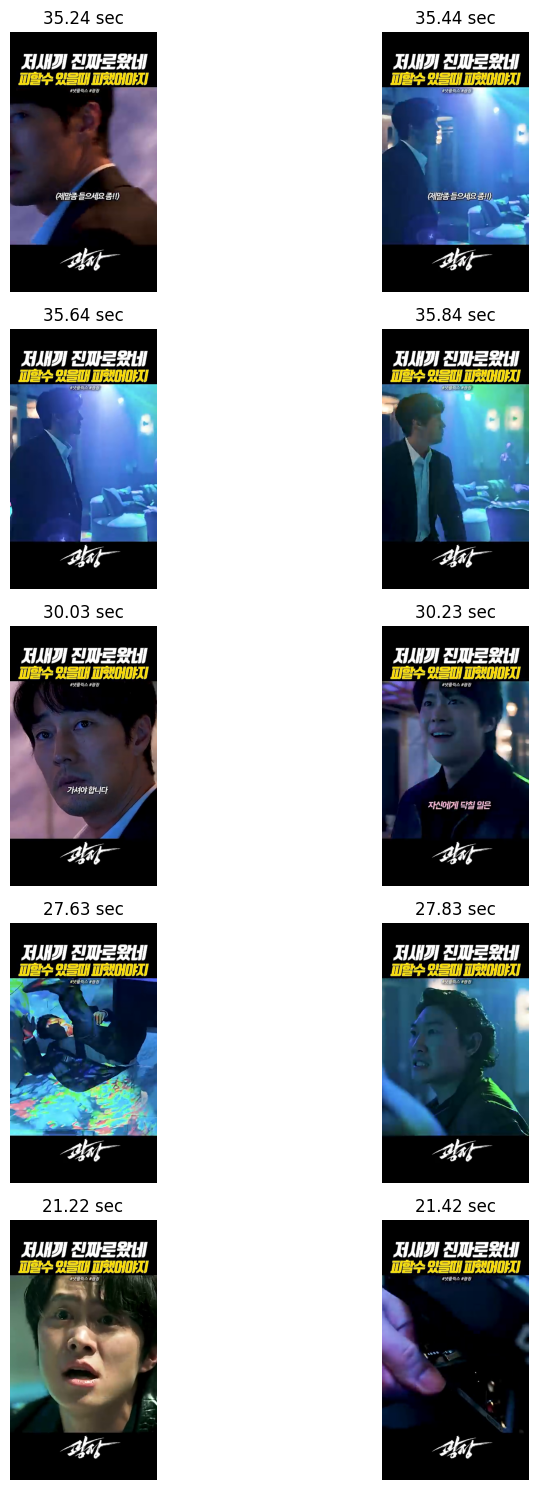

In [14]:
show_cut_candidates(
    test_video_path,
    similarity_df,
    n=5
)

- 화면 내용이 확연히 달라졌는데 유사도가 높게 나옴
- 화면 상단의 제목과 하단의 로고가 계속 동일하게 유지되기 때문
- 영상의 중앙 부분을 중심으로 컷을 탐지해보자..!

## 중앙 영역을 이용한 컷 탐지 실험

In [15]:
def check_center_similarity(video_path, sample_fps=5):

    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_step = max(1, round(fps / sample_fps))

    previous_hist = None
    similarities = []
    times = []

    frame_idx = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame_idx % frame_step == 0:

            # 위아래 20%씩 제외
            h, w = frame.shape[:2]
            center = frame[
                int(h * 0.2):int(h * 0.8), :
            ]

            # 크기 축소
            center = cv2.resize(center, (160, 90))

            # HSV 변환
            hsv = cv2.cvtColor(
                center, cv2.COLOR_BGR2HSV
            )

            # 색상 히스토그램
            hist = cv2.calcHist(
                [hsv], [0, 1], None,
                [30, 32],
                [0, 180, 0, 256]
            )

            cv2.normalize(hist, hist)

            if previous_hist is not None:

                similarity = cv2.compareHist(
                    previous_hist,
                    hist,
                    cv2.HISTCMP_CORREL
                )

                similarities.append(similarity)
                times.append(frame_idx / fps)

            previous_hist = hist

        frame_idx += 1

    cap.release()

    return pd.DataFrame({
        'time_sec': times,
        'similarity': similarities
    })

In [16]:
center_similarity_df = check_center_similarity(
    test_video_path
)

print("중앙 영역 유사도 통계:")
display(center_similarity_df['similarity'].describe())

print("\n중앙 영역 유사도가 낮은 10개 시점:")
display(
    center_similarity_df.nsmallest(
        10, 'similarity'
    )
)

중앙 영역 유사도 통계:


,similarity
count,233.000000
mean,0.841876
std,0.224639
min,0.013316
25%,0.829577
50%,0.933977
75%,0.976975
max,0.999274



중앙 영역 유사도가 낮은 10개 시점:


,time_sec,similarity
33,6.8068,0.013316
176,35.4354,0.047392
48,9.8098,0.064069
110,22.2222,0.070918
106,21.4214,0.113588
84,17.0170,0.135200
211,42.4424,0.141578
107,21.6216,0.182694
39,8.0080,0.193958
115,23.2232,0.207557


- 중앙 영역만 분석했을 때 유사도가 확실히 달라짐!!

### 중앙 영역 기준 컷 후보 확인

In [17]:
# 컷 탐지 기준
threshold = 0.5

# 유사도가 기준보다 낮은 시점 선택
cut_candidates = center_similarity_df[
    center_similarity_df['similarity'] < threshold
].copy()

# 시간순으로 정렬
cut_candidates = cut_candidates.sort_values('time_sec')

# 영상 길이
duration = 46.7467

# 컷 빈도 계산
cut_count = len(cut_candidates)
cut_frequency = cut_count / duration

print("컷 후보 개수:", cut_count)
print("초당 컷 후보 빈도:", round(cut_frequency, 4))

print("\n컷 후보 시점:")
display(cut_candidates.head(20))

컷 후보 개수: 24
초당 컷 후보 빈도: 0.5134

컷 후보 시점:


,time_sec,similarity
5,1.2012,0.318527
12,2.6026,0.410677
22,4.6046,0.264336
33,6.8068,0.013316
39,8.0080,0.193958
48,9.8098,0.064069
55,11.2112,0.215525
65,13.2132,0.404699
84,17.0170,0.135200
90,18.2182,0.303195


- 21.4214초	: 0.1136 & 21.6216초 : 0.1827
> 두 후보 사이의 간격이 약 0.2초밖에 되지 않음
- 눈으로 확인

### 컷 후보를 시각적으로 검증

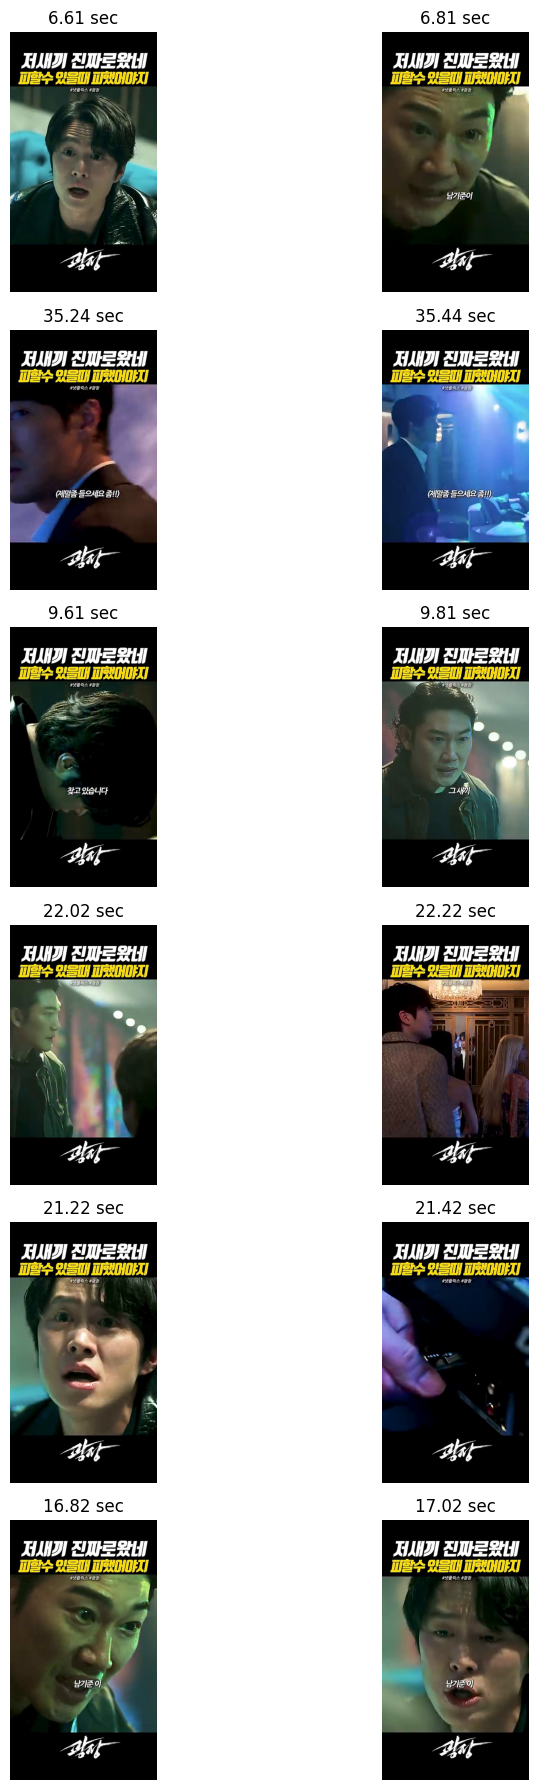

In [18]:
# 컷 후보 중 유사도가 가장 낮은 6개 확인
show_cut_candidates(
    test_video_path,
    cut_candidates,
    n=6
)

 - 음 굿!!

## 0.5 경계에 가까운 컷 후보 확인

기준값에 가까운 컷 후보:


,time_sec,similarity
150,30.2302,0.483681
143,28.8288,0.457361
181,36.4364,0.453420
131,26.4264,0.437305
128,25.8258,0.414363


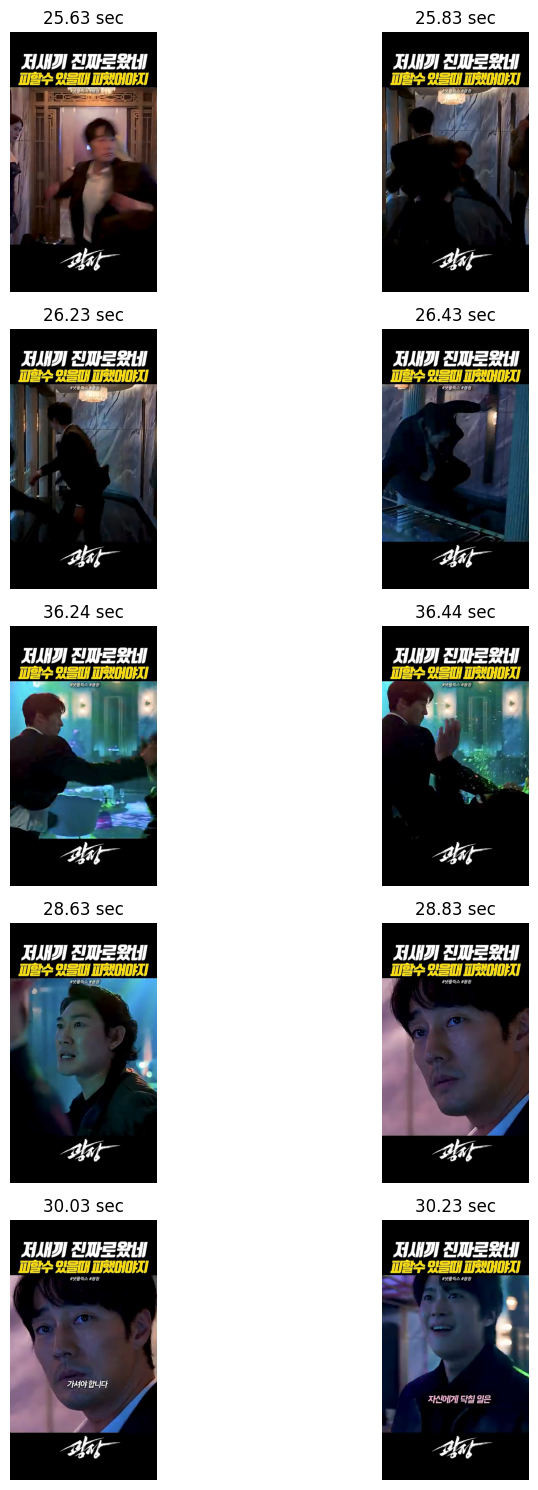

In [19]:
# threshold 0.5에 가장 가까운 컷 후보 5개
borderline_candidates = (
    cut_candidates
    .sort_values('similarity', ascending=False)
    .head(5)
)

print("기준값에 가까운 컷 후보:")
display(borderline_candidates)

# 실제 프레임 비교
show_cut_candidates(
    test_video_path,
    borderline_candidates,
    n=5
)

- 음 뭔가 약간 애매해서 다른 드라마에서도 컷 탐지 검증

In [20]:
# 현재 테스트 영상의 드라마 확인
test_drama = df.loc[
    df['video_id'] == test_video_id,
    'drama_name'
].iloc[0]

print("현재 테스트 드라마:", test_drama)

# 다른 드라마의 영상 중 하나 선택
other_video = df[
    (df['drama_name'] != test_drama) &
    (df['drama_name'].notna()) &
    (df['duration_sec'].between(20, 60))
].iloc[0]

print("\n새로운 테스트 영상 정보:")
print("video_id:", other_video['video_id'])
print("드라마:", other_video['drama_name'])
print("영상 길이:", other_video['duration_sec'])

현재 테스트 드라마: 광장

새로운 테스트 영상 정보:
video_id: NQt0VkR9q_0
드라마: 김씨 표류기
영상 길이: 46.0


In [21]:
# 두 번째 테스트 영상 ID
test_video_id2 = other_video['video_id']

# ZIP 내부 경로
test_zip_path2 = matched[test_video_id2][0]

# 코랩 임시 저장 경로
test_video_path2 = os.path.join(
    test_dir,
    f'{test_video_id2}.mp4'
)

# 영상 하나만 압축 해제
with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(test_zip_path2) as src:
        with open(test_video_path2, 'wb') as dst:
            import shutil
            shutil.copyfileobj(src, dst)

print("영상 ID:", test_video_id2)
print("저장 경로:", test_video_path2)
print("파일 크기(MB):",
      round(os.path.getsize(test_video_path2) / 1024**2, 2))

영상 ID: NQt0VkR9q_0
저장 경로: /content/traditional_test/NQt0VkR9q_0.mp4
파일 크기(MB): 3.96


In [22]:
# 중앙 영역 히스토그램 유사도 계산
center_similarity_df2 = check_center_similarity(
    test_video_path2,
    sample_fps=5
)

# 임시 기준값 0.5 적용
cut_candidates2 = center_similarity_df2[
    center_similarity_df2['similarity'] < 0.5
].copy()

# 실제 영상 길이 사용
duration2 = float(other_video['duration_sec'])

print("드라마:", other_video['drama_name'])
print("영상 길이:", duration2)

print("\n중앙 영역 유사도 통계:")
display(center_similarity_df2['similarity'].describe())

print("\n컷 후보 개수:", len(cut_candidates2))
print("초당 컷 후보 빈도:",
      round(len(cut_candidates2) / duration2, 4))

print("\n컷 후보 시점:")
display(cut_candidates2.head(10))

드라마: 김씨 표류기
영상 길이: 46.0

중앙 영역 유사도 통계:


,similarity
count,227.000000
mean,0.881803
std,0.223534
min,-0.012473
25%,0.910813
50%,0.981335
75%,0.992500
max,0.999580



컷 후보 개수: 19
초당 컷 후보 빈도: 0.413

컷 후보 시점:


,time_sec,similarity
11,2.4,0.392611
40,8.2,0.208079
49,10.0,0.156702
63,12.8,0.188674
68,13.8,0.314142
72,14.6,0.214937
73,14.8,0.244658
76,15.4,0.263723
89,18.0,0.132142
97,19.6,0.147443


유사도가 가장 낮은 컷 후보 5개


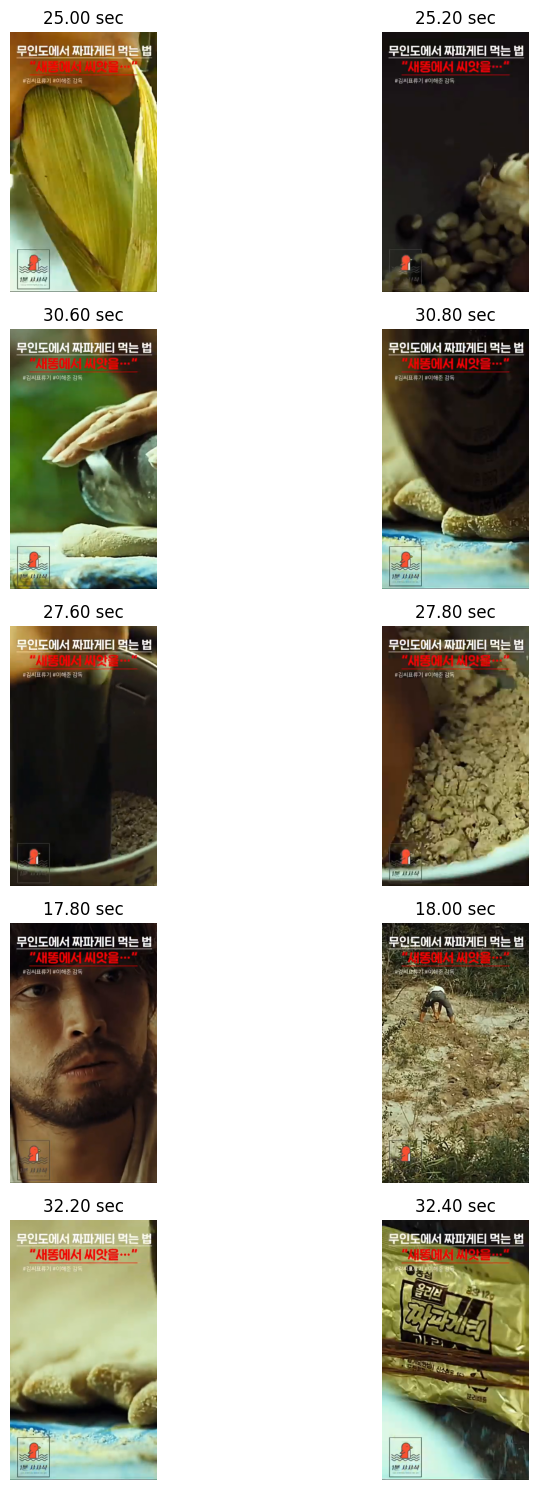

기준값에 가까운 컷 후보 5개


,time_sec,similarity
190,38.2,0.498337
170,34.2,0.463009
146,29.4,0.435388
11,2.4,0.392611
68,13.8,0.314142


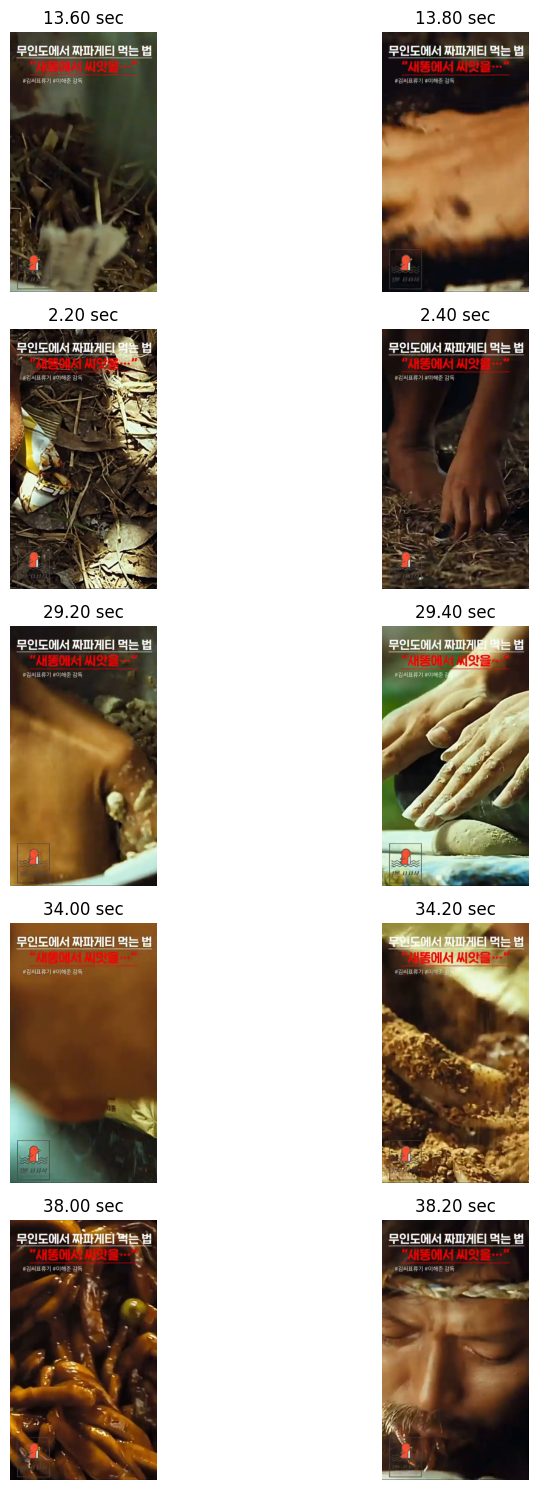

In [23]:
# 1. 유사도가 가장 낮은 컷 후보 5개
print("유사도가 가장 낮은 컷 후보 5개")

show_cut_candidates(
    test_video_path2,
    cut_candidates2,
    n=5
)

# 2. threshold 0.5에 가까운 컷 후보 5개
borderline_candidates2 = (
    cut_candidates2
    .sort_values('similarity', ascending=False)
    .head(5)
)

print("기준값에 가까운 컷 후보 5개")
display(borderline_candidates2)

show_cut_candidates(
    test_video_path2,
    borderline_candidates2,
    n=5
)

### 인접한 컷 후보 정리

In [25]:
def remove_nearby_cuts(candidates, min_interval=0.3):

    # 유사도가 낮은 후보부터 우선 선택
    sorted_candidates = candidates.sort_values('similarity')

    selected = []

    for _, row in sorted_candidates.iterrows():

        current_time = row['time_sec']

        # 이미 선택한 컷과 충분히 떨어져 있는지 확인
        if all(
            abs(current_time - t) >= min_interval
            for t in selected
        ):
            selected.append(current_time)

    return sorted(selected)

In [26]:
# 광장
cuts1 = remove_nearby_cuts(cut_candidates)

# 김씨 표류기
cuts2 = remove_nearby_cuts(cut_candidates2)

print("[광장]")
print("기존 컷 후보:", len(cut_candidates))
print("정리 후 컷 후보:", len(cuts1))
print("초당 컷 빈도:", round(len(cuts1) / 46.7467, 4))

print("\n[김씨 표류기]")
print("기존 컷 후보:", len(cut_candidates2))
print("정리 후 컷 후보:", len(cuts2))
print("초당 컷 빈도:", round(len(cuts2) / 46.0, 4))

print("\n광장 컷 시점:", cuts1)
print("\n김씨 표류기 컷 시점:", cuts2)

[광장]
기존 컷 후보: 24
정리 후 컷 후보: 23
초당 컷 빈도: 0.492

[김씨 표류기]
기존 컷 후보: 19
정리 후 컷 후보: 17
초당 컷 빈도: 0.3696

광장 컷 시점: [np.float64(1.2012), np.float64(2.6026000000000002), np.float64(4.6046000000000005), np.float64(6.8068), np.float64(8.008000000000001), np.float64(9.809800000000001), np.float64(11.2112), np.float64(13.2132), np.float64(17.017), np.float64(18.2182), np.float64(19.4194), np.float64(21.421400000000002), np.float64(22.2222), np.float64(23.223200000000002), np.float64(25.8258), np.float64(26.4264), np.float64(28.8288), np.float64(30.2302), np.float64(35.4354), np.float64(35.8358), np.float64(36.4364), np.float64(37.2372), np.float64(42.4424)]

김씨 표류기 컷 시점: [np.float64(2.4), np.float64(8.2), np.float64(10.0), np.float64(12.8), np.float64(13.8), np.float64(14.6), np.float64(15.4), np.float64(18.0), np.float64(19.6), np.float64(25.2), np.float64(26.2), np.float64(27.8), np.float64(29.4), np.float64(30.8), np.float64(32.4), np.float64(34.2), np.float64(38.2)]


# 움직임(Motion) 특징 추출 함수

In [27]:
def extract_motion_features(video_path, sample_fps=2):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return None

    fps = cap.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        cap.release()
        return None

    frame_step = max(1, round(fps / sample_fps))

    previous_gray = None
    motion_values = []

    frame_idx = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame_idx % frame_step == 0:

            frame = cv2.resize(frame, (160, 90))

            gray = cv2.cvtColor(
                frame, cv2.COLOR_BGR2GRAY
            )

            if previous_gray is not None:

                # Optical Flow 계산
                flow = cv2.calcOpticalFlowFarneback(
                    previous_gray,
                    gray,
                    None,
                    0.5,
                    3,
                    15,
                    3,
                    5,
                    1.2,
                    0
                )

                # 움직임 크기 계산
                magnitude, angle = cv2.cartToPolar(
                    flow[..., 0],
                    flow[..., 1]
                )

                motion_values.append(
                    float(magnitude.mean())
                )

            previous_gray = gray

        frame_idx += 1

    cap.release()

    if not motion_values:
        return None

    return {
        'trad_motion_mean': float(
            pd.Series(motion_values).mean()
        ),
        'trad_motion_std': float(
            pd.Series(motion_values).std(ddof=0)
        ),
        'trad_motion_max': float(
            pd.Series(motion_values).max()
        )
    }

In [28]:
# 광장
motion1 = extract_motion_features(test_video_path)

# 김씨 표류기
motion2 = extract_motion_features(test_video_path2)

print("[광장]")
print(motion1)

print("\n[김씨 표류기]")
print(motion2)

[광장]
{'trad_motion_mean': 2.7677707633664532, 'trad_motion_std': 1.1834609418745703, 'trad_motion_max': 6.289070129394531}

[김씨 표류기]
{'trad_motion_mean': 3.619012916088104, 'trad_motion_std': 1.797060411786343, 'trad_motion_max': 8.276315689086914}


- 평균 움직임: 「김씨 표류기」가 더 높음. 화면에서 추정된 움직임이 전반적으로 더 컸다는 의미
- 움직임 표준편차: 「김씨 표류기」가 더 높음. 움직임 크기의 변화가 상대적으로 다양했다는 뜻
- 최대 움직임: 「김씨 표류기」가 더 높음. 가장 큰 움직임이 관측된 구간의 값도 더 높음

> 컷 전환이 많은 영상이 반드시 화면 움직임도 큰 것은 아니라는 점

< 현재 추출된 특징 >

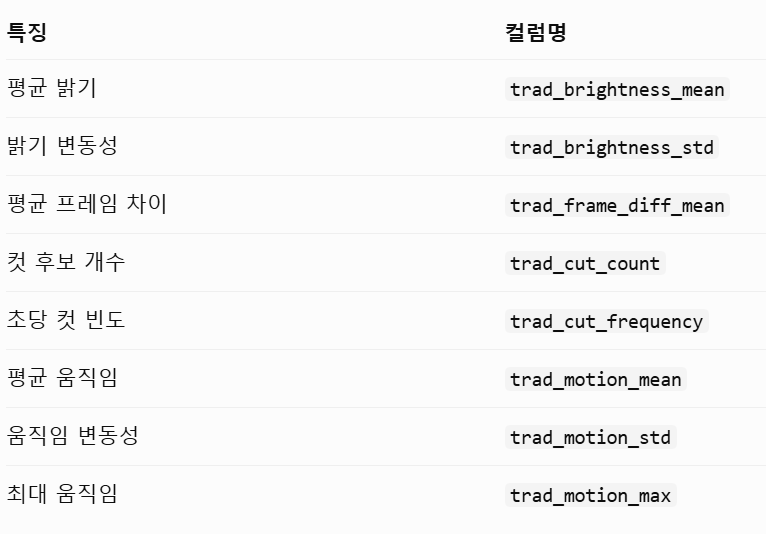

# 전체 영상 특징 추출 및 저장

In [31]:
# 결과 저장 경로
output_path = os.path.join(
    data_path, 'traditional_features.csv'
)

# 기존 결과가 있으면 불러오기
if os.path.exists(output_path):
    traditional_df = pd.read_csv(
        output_path, dtype={'video_id': str}
    )
else:
    traditional_df = pd.DataFrame()

# 이미 처리한 영상 ID
processed_ids = set(
    traditional_df['video_id'].astype(str)
) if 'video_id' in traditional_df.columns else set()

results = []

with zipfile.ZipFile(zip_path, 'r') as z:

    for i, video_id in enumerate(df['video_id'].astype(str), 1):

        if video_id in processed_ids:
            continue

        temp_path = os.path.join(
            test_dir, f'{video_id}.mp4'
        )

        try:
            # 1. ZIP에서 MP4 추출
            with z.open(matched[video_id][0]) as src:
                with open(temp_path, 'wb') as dst:
                    import shutil
                    shutil.copyfileobj(src, dst)

            # 2. 기본 특징 추출
            basic = extract_basic_features(temp_path)

            # 3. 컷 후보 추출
            similarity = check_center_similarity(temp_path)

            candidates = similarity[
                similarity['similarity'] < 0.5
            ]

            cuts = remove_nearby_cuts(
                candidates, min_interval=0.3
            )

            # 4. 움직임 특징 추출
            motion = extract_motion_features(temp_path)

            # 5. 영상 길이
            duration = float(
                df.loc[
                    df['video_id'] == video_id,
                    'duration_sec'
                ].iloc[0]
            )

            if basic is None or motion is None or duration <= 0:
                raise ValueError("특징 추출 실패")

            # 6. 특징 통합
            row = {
                'video_id': video_id,
                **basic,
                'trad_cut_count': len(cuts),
                'trad_cut_frequency': len(cuts) / duration,
                **motion
            }

            results.append(row)
            processed_ids.add(video_id)

        except Exception as e:
            print(f"오류 발생: {video_id} / {e}")

        finally:
            # 임시 MP4 삭제
            if os.path.exists(temp_path):
                os.remove(temp_path)

        # 20개마다 중간 저장
        if len(results) >= 20:
            traditional_df = pd.concat(
                [traditional_df, pd.DataFrame(results)],
                ignore_index=True
            )

            traditional_df.to_csv(
                output_path,
                index=False,
                encoding='utf-8-sig'
            )

            results = []
            print(f"{i}/1270 처리 진행 중")

# 남은 결과 저장
if results:
    traditional_df = pd.concat(
        [traditional_df, pd.DataFrame(results)],
        ignore_index=True
    )

traditional_df.to_csv(
    output_path,
    index=False,
    encoding='utf-8-sig'
)

print("\n특징 추출 완료")
print("저장 경로:", output_path)
print("데이터 크기:", traditional_df.shape)

20/1270 처리 진행 중
40/1270 처리 진행 중
60/1270 처리 진행 중
80/1270 처리 진행 중
100/1270 처리 진행 중
120/1270 처리 진행 중
140/1270 처리 진행 중
160/1270 처리 진행 중
180/1270 처리 진행 중
200/1270 처리 진행 중
220/1270 처리 진행 중
240/1270 처리 진행 중
260/1270 처리 진행 중
280/1270 처리 진행 중
300/1270 처리 진행 중
320/1270 처리 진행 중
340/1270 처리 진행 중
360/1270 처리 진행 중
380/1270 처리 진행 중
400/1270 처리 진행 중
420/1270 처리 진행 중
440/1270 처리 진행 중
460/1270 처리 진행 중
480/1270 처리 진행 중
500/1270 처리 진행 중
520/1270 처리 진행 중
540/1270 처리 진행 중
560/1270 처리 진행 중
580/1270 처리 진행 중
600/1270 처리 진행 중
620/1270 처리 진행 중
640/1270 처리 진행 중
660/1270 처리 진행 중
680/1270 처리 진행 중
700/1270 처리 진행 중
720/1270 처리 진행 중
740/1270 처리 진행 중
760/1270 처리 진행 중
780/1270 처리 진행 중
800/1270 처리 진행 중
820/1270 처리 진행 중
840/1270 처리 진행 중
860/1270 처리 진행 중
880/1270 처리 진행 중
900/1270 처리 진행 중
920/1270 처리 진행 중
940/1270 처리 진행 중
960/1270 처리 진행 중
980/1270 처리 진행 중
1000/1270 처리 진행 중
1020/1270 처리 진행 중
1040/1270 처리 진행 중
1060/1270 처리 진행 중
1080/1270 처리 진행 중
1100/1270 처리 진행 중
1120/1270 처리 진행 중
1140/1270 처리 진행 중
1160/1270 처리 진행 중
1180/1270

In [32]:
print("데이터 크기:", traditional_df.shape)

print("\nvideo_id 중복 개수:")
print(traditional_df['video_id'].duplicated().sum())

print("\n누락된 영상 수:")
print(
    len(
        set(df['video_id']) -
        set(traditional_df['video_id'])
    )
)

print("\n특징별 결측값:")
print(traditional_df.isnull().sum())

print("\n데이터 미리보기:")
display(traditional_df.head())

데이터 크기: (1270, 9)

video_id 중복 개수:
0

누락된 영상 수:
0

특징별 결측값:
video_id                0
trad_brightness_mean    0
trad_brightness_std     0
trad_frame_diff_mean    0
trad_cut_count          0
trad_cut_frequency      0
trad_motion_mean        0
trad_motion_std         0
trad_motion_max         0
dtype: int64

데이터 미리보기:


,video_id,trad_brightness_mean,trad_brightness_std,trad_frame_diff_mean,trad_cut_count,trad_cut_frequency,trad_motion_mean,trad_motion_std,trad_motion_max
0,NQt0VkR9q_0,84.801148,21.770071,49.444384,17,0.369565,3.619013,1.797060,8.276316
1,ExRxa0wD3j4,99.983671,30.503028,57.218027,18,0.418605,3.405504,1.621436,7.243001
2,86EflpUcel0,105.185284,17.596834,49.242087,6,0.300000,3.673920,2.534105,10.236567
3,EN2QjA52vwE,87.654302,23.598859,57.663258,18,0.642857,4.157267,1.758647,7.661309
4,GRajxajB8aA,77.173350,20.929414,47.973372,13,0.464286,2.978673,1.899618,11.106164
